# IS6400 Week 5: Clustering
LI Binxiong | 60234350

This notebook contains the course tutorial followed by my answers to Questions 1–5. The Iris models use all four measurements. Petal width and sepal length are used for the scatter plots.

In [1]:
from pathlib import Path
import os, sys, hashlib, platform
COURSE_DIR = Path(r"D:/上课资料/CityU/IS6400_Business_Data_Analytics")
DATA_DIR = COURSE_DIR / "course_files_export"
PROJECT_DATA = COURSE_DIR / "assignment/graded/A06-group-project/work/data/raw"
assert (DATA_DIR / "iris.txt").is_file(), "Check COURSE_DIR in this cell"
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["MKL_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"
os.chdir(DATA_DIR)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, sklearn, scipy
from threadpoolctl import threadpool_limits
thread_limit = threadpool_limits(limits=1)
from IPython.display import display, HTML, Markdown
pd.options.display.float_format = "{:.6f}".format
pd.options.display.max_colwidth = None
plt.rcParams.update({"font.size":12, "figure.dpi":110})
display(HTML("""<style>
.jp-Notebook {max-width:1080px;margin:auto;}
.jp-RenderedHTMLCommon {font-size:18px;line-height:1.65;}
.jp-RenderedHTMLCommon table {font-size:16px;}
.jp-RenderedHTMLCommon td {overflow-wrap:anywhere;max-width:600px;}
.highlight pre,.jp-InputArea pre,.jp-OutputArea pre {font-size:14px !important;line-height:1.5 !important;}
.jp-RenderedHTMLCommon img {max-width:100%;height:auto;}
</style>"""))



## Course tutorial
The following cells reproduce the examples provided in the course notebook.

# Cluster Analysis

The following tutorial contains Python examples for solving clustering problems. You should refer to Chapters 7 and 8 of the "Introduction to Data Mining" book, and slides week 5 to understand some of the concepts introduced in this tutorial.

Cluster analysis seeks to partition the input data into groups of closely related instances so that instances that belong to the same cluster are more similar to each other than to instances that belong to other clusters. 

In this tutorial, we will provide examples of using different clustering techniques provided by the scikit-learn library package. We will cover:
1. K-means Clustering (Partitional)
2. Hierarchical Clustering (Single, Complete, Average, and Ward's Method)
3. Density-Based Clustering (DBSCAN)
4. Spectral Clustering (Graph-based)

Read the step-by-step instructions below carefully. To execute the code, click on the corresponding cell and press the SHIFT-ENTER keys simultaneously.

In [2]:
import warnings
import os
warnings.filterwarnings("ignore") 
os.environ['LOKY_MAX_CPU_COUNT'] = '1' 

# Summary of toolbox

1. KMeans clustering. from sklearn.cluster import KMeans
https://scikit-learn.org/stable/modules/generated/sklearn.cluster.KMeans.html 

2. Hierarchy clustering. from scipy.cluster import hierarchy
https://docs.scipy.org/doc/scipy/reference/cluster.hierarchy.html

3. DBSCAN. from sklearn.cluster import DBSCAN
https://scikit-learn.org/stable/modules/generated/sklearn.cluster.DBSCAN.html#sklearn.cluster.DBSCAN

4. SpectralClustering. from sklearn.cluster import SpectralClustering
https://scikit-learn.org/stable/modules/generated/sklearn.cluster.SpectralClustering.html#sklearn.cluster.SpectralClustering 



## 1 K-means Clustering

The k-means clustering algorithm represents each cluster by its corresponding cluster centroid. The algorithm would partition the input data into *k* disjoint clusters by iteratively applying the following two steps:
1. Form *k* clusters by assigning each instance to its nearest centroid.
2. Recompute the centroid of each cluster.

In this section, we perform k-means clustering on a toy example of movie ratings dataset. We first create the dataset as follows.

In [3]:
import pandas as pd

ratings = [['john',5,5,2,1],['mary',4,5,3,2],['bob',4,4,4,3],['lisa',2,2,4,5],['lee',1,2,3,4],['harry',2,1,5,5]]
titles = ['user','Jaws','Star Wars','Exorcist','Omen']

#generate datafame: inlcuding user name and users' ratings of four movies
movies = pd.DataFrame(ratings,columns=titles) 

movies

,user,Jaws,Star Wars,Exorcist,Omen
0,john,5,5,2,1
1,mary,4,5,3,2
2,bob,4,4,4,3
3,lisa,2,2,4,5
4,lee,1,2,3,4
5,harry,2,1,5,5


In this example dataset, the first 3 users liked action movies (Jaws and Star Wars) while the last 3 users enjoyed horror movies (Exorcist and Omen). Our goal is to apply k-means clustering on the users to identify groups of users with similar movie preferences.

The example below shows how to apply k-means clustering (with k=2) on the movie ratings data. We must remove the "user" column first before applying the clustering algorithm. The cluster assignment for each user is displayed as a dataframe object.

In [4]:
from sklearn.cluster import KMeans

data = movies.drop('user',axis=1) # we only use the ratings as features, so the 'user' column is dropped.
k_means = KMeans(n_clusters=2, max_iter=50, random_state=1) # cluster the six users into two clusters.
# max_iter: Maximum number of iterations of the k-means algorithm for a single run.
k_means.fit(data)
labels = k_means.labels_
pd.DataFrame(labels, index=movies.user, columns=['Cluster ID'])

,Cluster ID
user,
john,0
mary,0
bob,0
lisa,1
lee,1
harry,1


The k-means clustering algorithm assigns the first three users to one cluster and the last three users to the second cluster. The results are consistent with our expectation. We can also display the centroid for each of the two clusters.

In [5]:
centroids = k_means.cluster_centers_
pd.DataFrame(centroids,columns=data.columns)

,Jaws,Star Wars,Exorcist,Omen
0,4.333333,4.666667,3.000000,2.000000
1,1.666667,1.666667,4.000000,4.666667


Observe that cluster 0 has higher ratings for the horror movies whereas cluster 1 has higher ratings for action movies. The cluster centroids can be applied to other users to determine their cluster assignments. 

In this run, cluster 0 has higher action-movie ratings and cluster 1 has higher horror-movie ratings. The original description above uses the opposite numbering. The centre values identify the preferences; the cluster numbers can be swapped without changing the groups.

In [6]:
import numpy as np

testData = np.array([[4,5,1,2],[3,2,4,4],[2,3,4,1],[3,2,3,3],[5,4,1,4]])
labels = k_means.predict(testData)
labels = labels.reshape(-1,1)
usernames = np.array(['paul','kim','liz','tom','bill']).reshape(-1,1)
cols = movies.columns.tolist()
cols.append('Cluster ID')
newusers = pd.DataFrame(np.concatenate((usernames, testData, labels), axis=1),columns=cols)
newusers

,user,Jaws,Star Wars,Exorcist,Omen,Cluster ID
0,paul,4,5,1,2,0
1,kim,3,2,4,4,1
2,liz,2,3,4,1,0
3,tom,3,2,3,3,1
4,bill,5,4,1,4,0


## 2 Hierarchical Clustering

This section demonstrates examples of applying hierarchical clustering to the `vertebrate.csv` . Specifically, we illustrate the results of using 4 hierarchical clustering algorithms provided by the Python scipy library: (1) single link (MIN), (2) complete link (MAX), (3) group average, and (4) Ward's method.  Other hierarchical clustering algorithms provided by the library include centroid-based.

In [7]:
import pandas as pd

data = pd.read_csv('vertebrate.csv',header='infer')
data

,Name,Warm-blooded,Gives Birth,Aquatic Creature,Aerial Creature,Has Legs,Hibernates,Class
0,human,1,1,0,0,1,0,mammals
1,python,0,0,0,0,0,1,reptiles
2,salmon,0,0,1,0,0,0,fishes
3,whale,1,1,1,0,0,0,mammals
4,frog,0,0,1,0,1,1,amphibians
5,komodo,0,0,0,0,1,0,reptiles
6,bat,1,1,0,1,1,1,mammals
7,pigeon,1,0,0,1,1,0,birds
8,cat,1,1,0,0,1,0,mammals
9,leopard shark,0,1,1,0,0,0,fishes


### 2.1 Single Link (MIN)

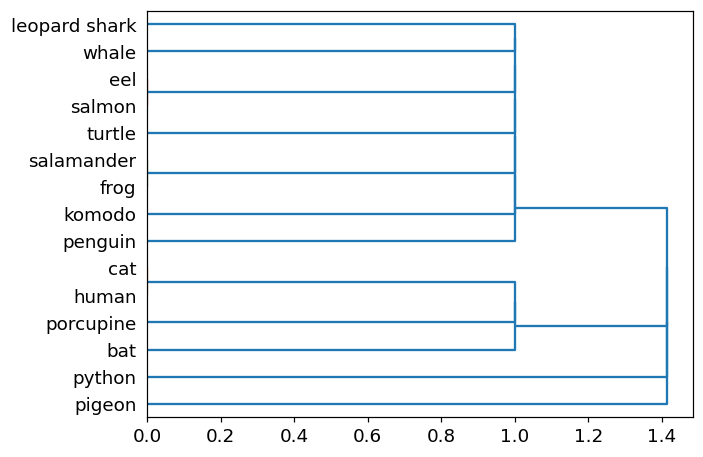

In [8]:
from scipy.cluster import hierarchy
import matplotlib.pyplot as plt
%matplotlib inline

names = data['Name']
Y = data['Class']
X = data.drop(['Name','Class'],axis=1)
Z = hierarchy.linkage(X.values, 'single') #hierarchy clusting using 'single' link
dn = hierarchy.dendrogram(Z,labels=names.tolist(),orientation='right') #plot dendrogram
plt.show()

### 2.2 Complete Link (MAX)

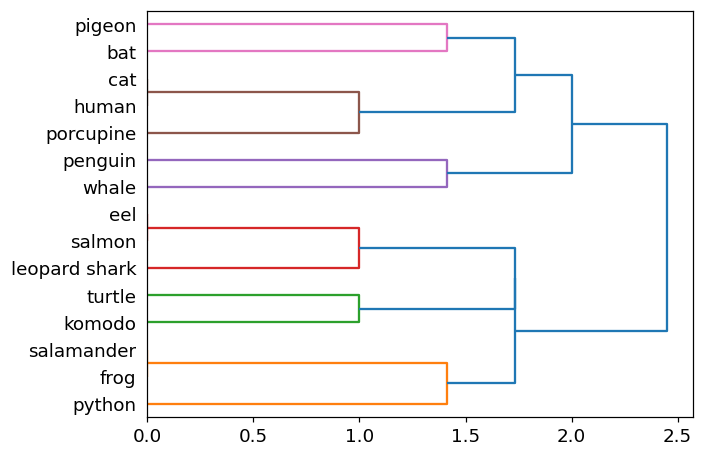

In [9]:
Z = hierarchy.linkage(X.values, 'complete') #change to 'complete' link
dn = hierarchy.dendrogram(Z,labels=names.tolist(),orientation='right')
plt.show()

### 2.3 Group Average

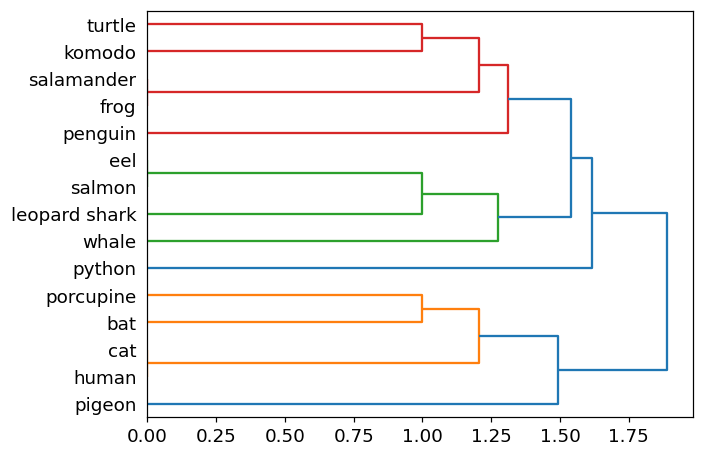

In [10]:
Z = hierarchy.linkage(X.values, 'average')
dn = hierarchy.dendrogram(Z,labels=names.tolist(),orientation='right')
plt.show()

### 2.4 Ward's Method (Minimum Variance)

Ward's method is another popular approach for hierarchical clustering, mentioned in the lecture slides. Unlike Single Link (MIN) or Complete Link (MAX), Ward's method minimizes the total within-cluster variance. At each step, it merges the pair of clusters that leads to the minimum increase in total within-cluster variance. This tends to produce clusters that are relatively equal in size and spherical in shape. It is implemented in `scipy` using `method='ward'`.

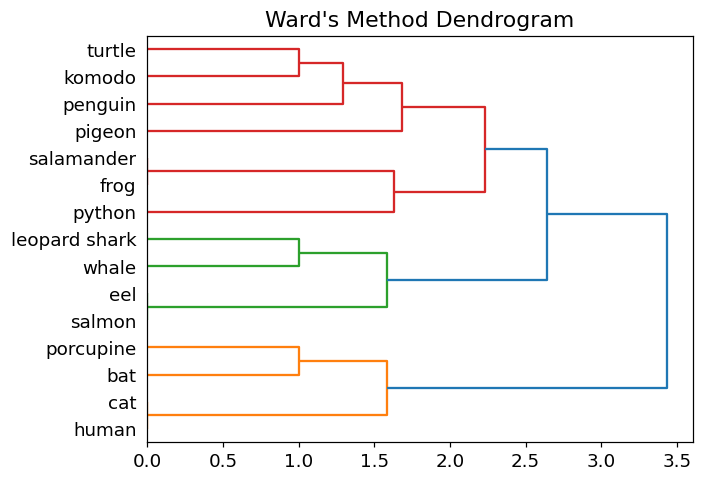

In [11]:
Z = hierarchy.linkage(X.values, 'ward') # Ward's method
dn = hierarchy.dendrogram(Z, labels=names.tolist(), orientation='right')
plt.title("Ward's Method Dendrogram")
plt.show()

### 2.5 Comparing Linkage Methods on Different Data Shapes

Reference Link: [Comparing different hierarchical linkage methods on toy datasets (scikit-learn)](https://scikit-learn.org/stable/auto_examples/cluster/plot_linkage_comparison.html)

Different linkage methods perform very differently depending on the geometry of your data. There is no single "best" algorithm.


We will compare:
*   Single Link (MIN)
*   Complete Link (MAX)
*   Average Link
*   Ward's Method

Run the code below to see how the same algorithm generates completely different results just by changing the data shape or the linkage method!

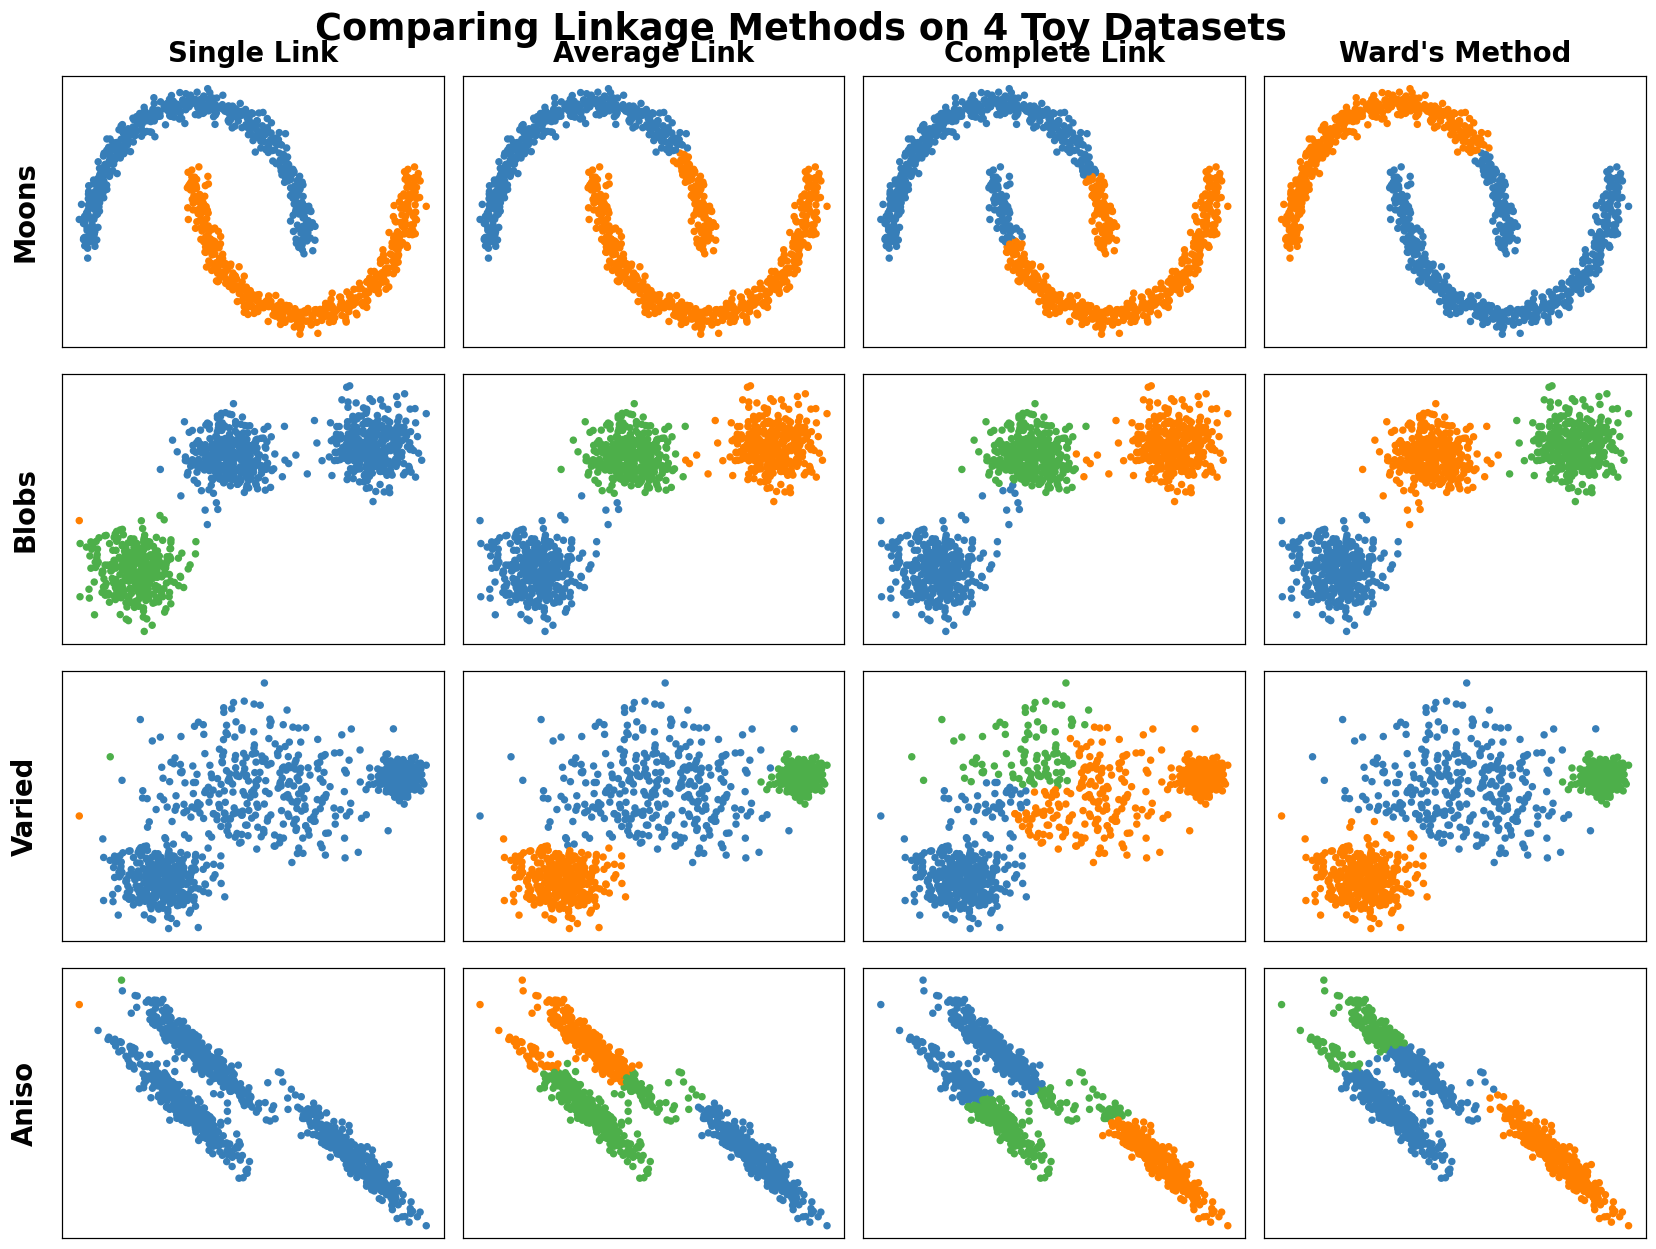

In [12]:
import warnings
from itertools import cycle, islice
import matplotlib.pyplot as plt
import numpy as np
from sklearn import cluster, datasets
from sklearn.preprocessing import StandardScaler

# 1. Generate 4 selected datasets
n_samples = 1000
moons = datasets.make_moons(n_samples=n_samples, noise=0.05, random_state=170)
blobs = datasets.make_blobs(n_samples=n_samples, random_state=170)
varied = datasets.make_blobs(n_samples=n_samples, cluster_std=[1.0, 2.5, 0.5], random_state=170)
X, _ = datasets.make_blobs(n_samples=n_samples, random_state=170)
transformation = [[0.6, -0.6], [-0.4, 0.8]]
X_aniso = np.dot(X, transformation)

datasets = [
    ("Moons", moons[0], 2),
    ("Blobs", blobs[0], 3),
    ("Varied", varied[0], 3),
    ("Aniso", X_aniso, 3)
]

# 2. Set up the plot
plt.figure(figsize=(16, 12))
plt.subplots_adjust(left=0.08, right=0.98, bottom=0.02, top=0.90, wspace=0.05, hspace=0.1)

plot_num = 1
algorithms = ["Single Link", "Average Link", "Complete Link", "Ward's Method"]

# 3. Loop through datasets and algorithms
for i, (name, X, n_clusters) in enumerate(datasets):
    X = StandardScaler().fit_transform(X)
    
    clustering_algorithms = (
        ("Single Link", cluster.AgglomerativeClustering(n_clusters=n_clusters, linkage="single")),
        ("Average Link", cluster.AgglomerativeClustering(n_clusters=n_clusters, linkage="average")),
        ("Complete Link", cluster.AgglomerativeClustering(n_clusters=n_clusters, linkage="complete")),
        ("Ward's Method", cluster.AgglomerativeClustering(n_clusters=n_clusters, linkage="ward")),
    )

    for j, (algo_name, algorithm) in enumerate(clustering_algorithms):
        with warnings.catch_warnings():
            warnings.filterwarnings("ignore")
            algorithm.fit(X)
        
        y_pred = algorithm.labels_.astype(int)
        ax = plt.subplot(len(datasets), len(clustering_algorithms), plot_num)
        
        if i == 0:
            ax.set_title(algo_name, size=18, fontweight='bold', pad=10)
        if j == 0:
            ax.set_ylabel(name, size=18, fontweight='bold', labelpad=15)

        colors = np.array(list(islice(cycle(["#377eb8", "#ff7f00", "#4daf4a", "#f781bf"]), int(max(y_pred) + 1))))
        ax.scatter(X[:, 0], X[:, 1], s=15, color=colors[y_pred])
        ax.set_xticks(()); ax.set_yticks(())
        
        plot_num += 1

plt.suptitle("Comparing Linkage Methods on 4 Toy Datasets", fontsize=24, y=0.95, fontweight='bold')
plt.show()

## 3 Density-Based Clustering

Density-based clustering identifies the individual clusters as high-density regions that are separated by regions of low density. DBScan is one of the most popular density based clustering algorithms. In DBScan, data points are classified into 3 types---core points, border points, and noise points---based on the density of their local neighborhood. The local neighborhood density is defined according to 2 parameters:  radius of neighborhood size (eps) and minimum number of points in the neighborhood (min_samples). 

For this approach, we will use a noisy, 2-dimensional dataset originally created by Karypis et al. [1] for evaluating their proposed CHAMELEON algorithm. The example code shown below will load and plot the distribution of the data.

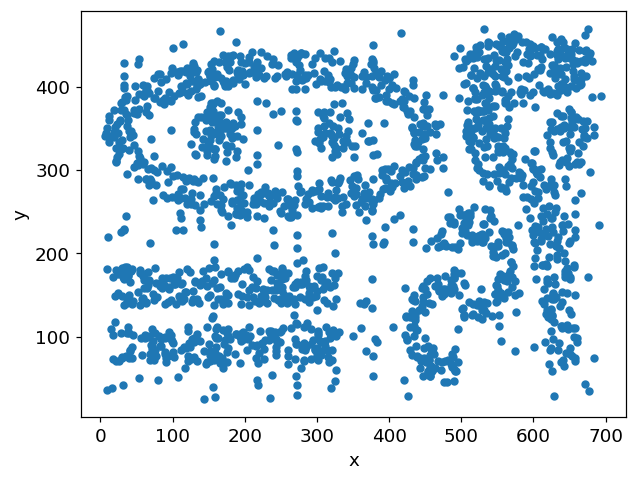

In [13]:
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline

data = pd.read_csv('chameleon.data', delimiter=' ', names=['x','y'])
ax1=data.plot.scatter(x='x',y='y')
plt.show()

We apply the DBScan clustering algorithm on the data by setting the neighborhood radius (eps) to 15.5 and minimum number of points (min_samples) to be 5. The clusters are assigned to IDs between 0 to 8 while the noise points are assigned to a cluster ID equals to -1.

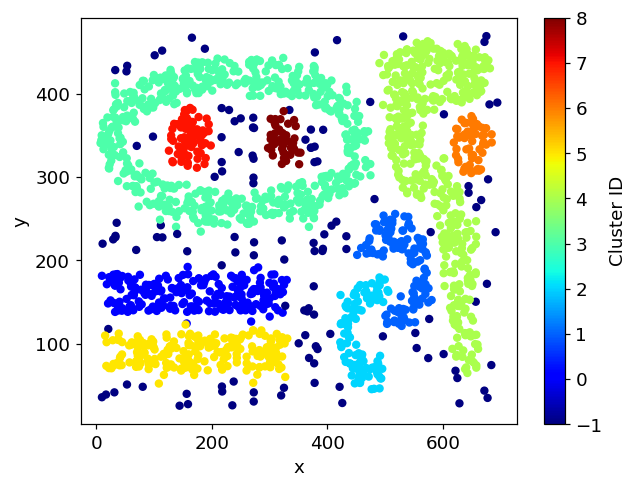

In [14]:
from sklearn.cluster import DBSCAN

db = DBSCAN(eps=15.5, min_samples=5).fit(data)
core_samples_mask = np.zeros_like(db.labels_, dtype=bool)
core_samples_mask[db.core_sample_indices_] = True
labels = pd.DataFrame(db.labels_,columns=['Cluster ID'])
result = pd.concat((data,labels), axis=1)
ax1=result.plot.scatter(x='x',y='y',c='Cluster ID', colormap='jet')
plt.show()

## 4 Spectral Clustering

One of the main limitations of the k-means clustering algorithm is its tendency to seek for globular-shaped clusters. Thus, it does not work when applied to datasets with arbitrary-shaped clusters or when the cluster centroids overlapped with one another. Spectral clustering can overcome this limitation by exploiting properties of the similarity graph to overcome such limitations. To illustrate this, consider the following two-dimensional datasets.

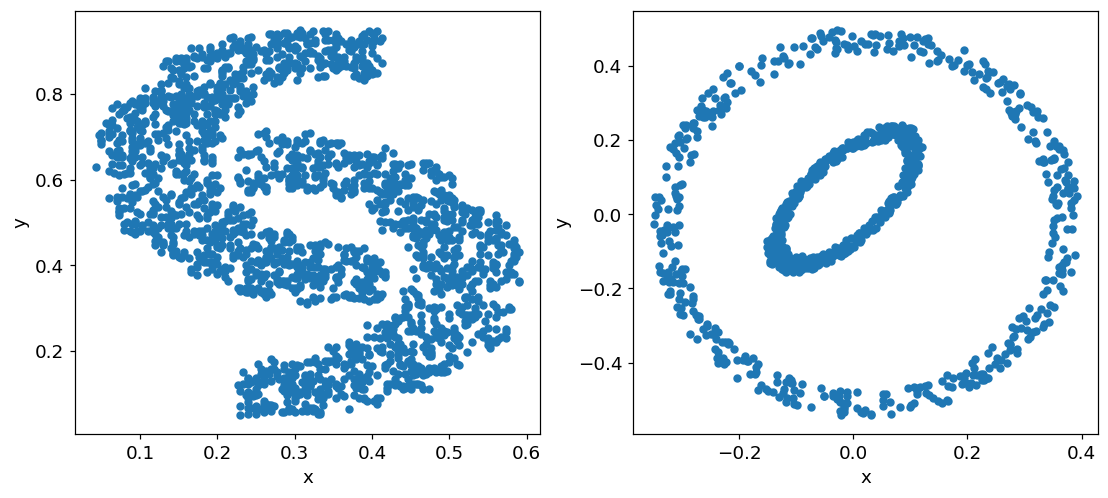

In [15]:
import pandas as pd

data1 = pd.read_csv('2d_data.txt', delimiter=' ', names=['x','y'])
data2 = pd.read_csv('elliptical.txt', delimiter=' ', names=['x','y'])

fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12,5))
data1.plot.scatter(x='x',y='y',ax=ax1)
data2.plot.scatter(x='x',y='y',ax=ax2)
plt.show()

Below, we demonstrate the results of applying k-means to the datasets (with k=2).

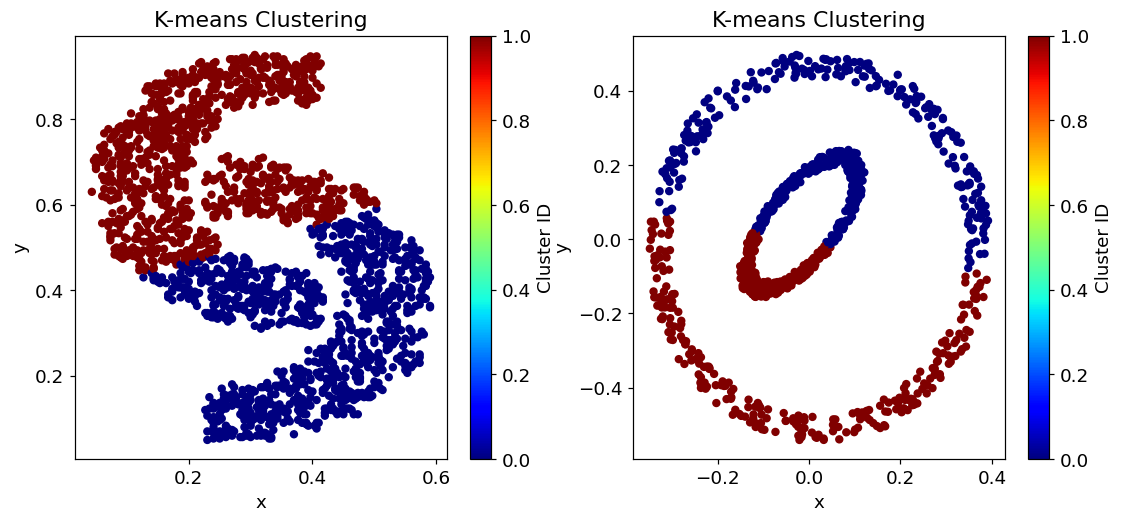

In [16]:
from sklearn import cluster

k_means = cluster.KMeans(n_clusters=2, max_iter=50, random_state=1)
k_means.fit(data1)
labels1 = pd.DataFrame(k_means.labels_,columns=['Cluster ID'])
result1 = pd.concat((data1,labels1), axis=1)

k_means2 = cluster.KMeans(n_clusters=2, max_iter=50, random_state=1)
k_means2.fit(data2)
labels2 = pd.DataFrame(k_means2.labels_,columns=['Cluster ID'])
result2 = pd.concat((data2,labels2), axis=1)

fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12,5))
result1.plot.scatter(x='x',y='y',c='Cluster ID',colormap='jet',ax=ax1)
ax1.set_title('K-means Clustering')
result2.plot.scatter(x='x',y='y',c='Cluster ID',colormap='jet',ax=ax2)
ax2.set_title('K-means Clustering')
plt.show()

The plots above show the poor performance of k-means clustering. Next, we apply spectral clustering to the datasets. Spectral clustering converts the data into a similarity graph and applies the normalized cut graph partitioning algorithm to generate the clusters. In the example below, we use the Gaussian radial basis function as our affinity (similarity) measure. Users need to tune the kernel parameter (gamma) value in order to obtain the appropriate clusters for the given dataset. 

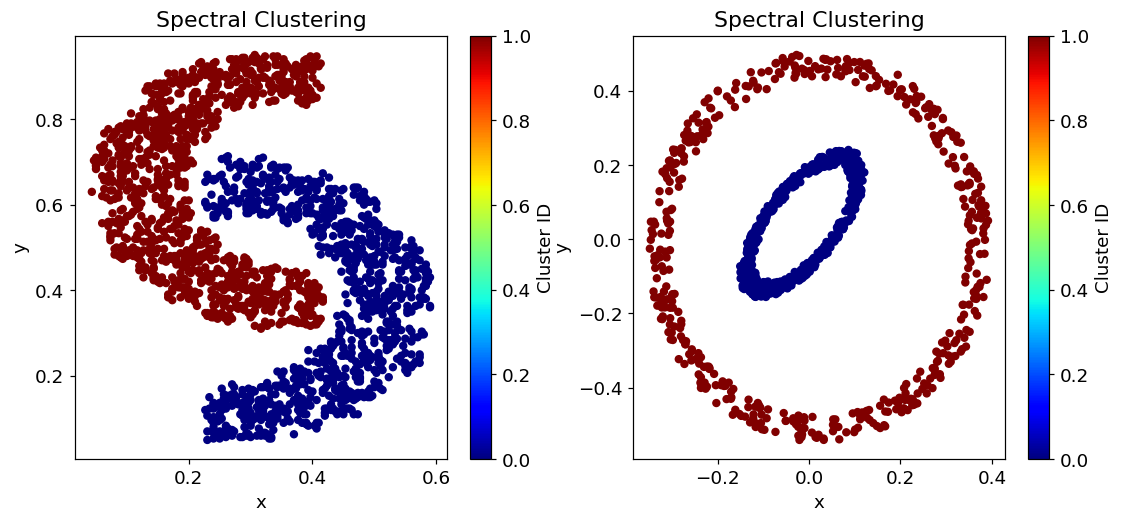

In [17]:
from sklearn.cluster import SpectralClustering
import pandas as pd

spectral = SpectralClustering(n_clusters=2,random_state=1,affinity='rbf',gamma=5000)
spectral.fit(data1)
labels1 = pd.DataFrame(spectral.labels_,columns=['Cluster ID'])
result1 = pd.concat((data1,labels1), axis=1)

spectral2 = SpectralClustering(n_clusters=2,random_state=1,affinity='rbf',gamma=500)
spectral2.fit(data2)
labels2 = pd.DataFrame(spectral2.labels_,columns=['Cluster ID'])
result2 = pd.concat((data2,labels2), axis=1)

fig, (ax1,ax2) = plt.subplots(nrows=1, ncols=2, figsize=(12,5))
result1.plot.scatter(x='x',y='y',c='Cluster ID',colormap='jet',ax=ax1)
ax1.set_title('Spectral Clustering')
result2.plot.scatter(x='x',y='y',c='Cluster ID',colormap='jet',ax=ax2)
ax2.set_title('Spectral Clustering')
plt.show()

## 5. Summary

This tutorial illustrates examples of using different Python's implementation of clustering algorithms. Algorithms such as k-means, spectral clustering, and DBScan are designed to create disjoint partitions of the data whereas the single-link, complete-link, and group average algorithms are designed to generate a hierarchy of cluster partitions.

References:
[1] George Karypis, Eui-Hong Han, and Vipin Kumar. CHAMELEON: A Hierarchical Clustering Algorithm Using Dynamic Modeling. IEEE Computer 32(8): 68-75, 1999.

# Week 5 assignment

### 1. Apply KMeans (K=3) to the Iris dataset (excluding the "class" attribute). Use 'petal width' and 'sepal length' to create a scatter plot and use cluster label as color. [10 points]

### 2. Apply BisectingKMeans (K=3) to the Iris dataset (excluding the "class" attribute). Briefly explain how its hierarchical partitioning mechanism differs from standard K-means. Reference link: [BisectingKMeans](https://scikit-learn.org/stable/modules/generated/sklearn.cluster.BisectingKMeans.html#sklearn.cluster.BisectingKMeans) [20 points]

### 3. Choose one density-based clustering algorithm and present the clustering results on the Iris dataset (excluding the "class" attribute). Tune its parameters and identify how many data points are classified as noise (-1). [20 points]

### 4. Based on the 4x4 grid plot in Section 2.5 of the tutorial (Moons, Blobs, Varied, Aniso), summarize which linkage method (Single, Average, Complete, or Ward's) is most suitable for which type of data shape, and state your final rule of thumb for selecting a linkage method. [20 points]

### 5. Review and compare different clustering algorithms and choose one clustering algorithm for your course project dataset. Reference link: [Clustering Algorithms](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html#sphx-glr-auto-examples-cluster-plot-cluster-comparison-py) [30 points]

# Assignment answers
## Q1. K-means on Iris
I excluded the class column and fitted K-means to all four measurements in centimetres. I kept the original scale for Q1 and Q2 so that both methods use the same distances. The effect of standardisation is examined in the additional analysis.

In [18]:
from sklearn.cluster import KMeans, BisectingKMeans, DBSCAN, AgglomerativeClustering
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn import datasets as toy_datasets
import warnings
warnings.resetwarnings()
iris = pd.read_csv(DATA_DIR / "iris.txt", header=None,
                   names=["sepal length","sepal width","petal length","petal width","class"])
X_iris = iris.drop(columns="class")
assert X_iris.shape == (150, 4)
assert not X_iris.isna().any().any()
assert np.isfinite(X_iris.to_numpy()).all()
display(X_iris.head())
print("Rows:", len(X_iris), "Features:", X_iris.shape[1])
display(X_iris.agg(["min","max"]))

,sepal length,sepal width,petal length,petal width
0,5.100000,3.500000,1.400000,0.200000
1,4.900000,3.000000,1.400000,0.200000
2,4.700000,3.200000,1.300000,0.200000
3,4.600000,3.100000,1.500000,0.200000
4,5.000000,3.600000,1.400000,0.200000


Rows: 150 Features: 4


,sepal length,sepal width,petal length,petal width
min,4.300000,2.000000,1.000000,0.100000
max,7.900000,4.400000,6.900000,2.500000


There are 150 flowers, four numerical features and no missing values.

K-means assigns each flower to its nearest centre, then replaces each centre with the mean of its group. It repeats these steps until the solution converges or reaches the iteration limit. I used K = 3, 20 initialisations and random seed 42. The run with the lowest sum of squared distances is retained:

$$
J=\sum_{i=1}^{n}\left\|x_i-\mu_{c_i}\right\|^2.
$$

Here, $x_i$ is a flower's four measurements and $\mu_{c_i}$ is the centre of its assigned group. The distance sums the squared differences across the four features. Taking the mean minimises this sum within each group. Twenty starts reduce sensitivity to the initial centres, although they do not guarantee the best possible partition.

In [19]:
km = KMeans(n_clusters=3, n_init=20, random_state=42, max_iter=300, tol=1e-4)
km_labels = km.fit_predict(X_iris)
print(f"K-means inertia: {km.inertia_:.6f}")
print(f"K-means silhouette: {silhouette_score(X_iris, km_labels):.6f}")
print("Iterations:", km.n_iter_)
display(pd.Series(km_labels, name="cluster").value_counts().sort_index().rename("count").to_frame())
display(pd.DataFrame(km.cluster_centers_, columns=X_iris.columns).rename_axis("cluster"))

K-means inertia: 78.940841
K-means silhouette: 0.552592
Iterations: 4


,count
cluster,
0,62
1,50
2,38


,sepal length,sepal width,petal length,petal width
cluster,,,,
0,5.901613,2.748387,4.393548,1.433871
1,5.006000,3.418000,1.464000,0.244000
2,6.850000,3.073684,5.742105,2.071053


The three clusters contain **62**, **50** and **38** flowers. Their total squared distance is **78.940841**, and the silhouette score is **0.552592**. Silhouette compares how close a point is to its own group with how close it is to the nearest other group. The score suggests some separation, with overlap remaining.

Figure 1 uses petal width on the horizontal axis and sepal length on the vertical axis. Colour shows the fitted cluster, not the known species. The model still uses all four features.

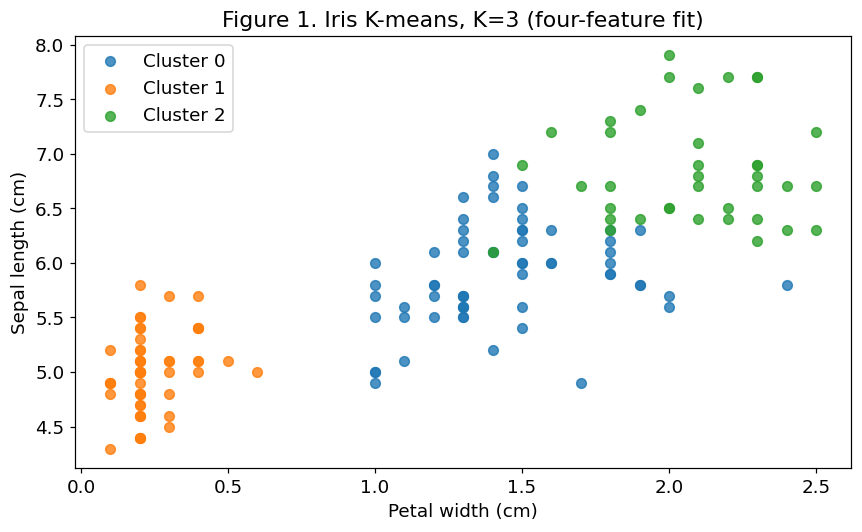

In [20]:
fig, ax = plt.subplots(figsize=(8, 5))
for label in np.unique(km_labels):
    mask = km_labels == label
    ax.scatter(X_iris.loc[mask,"petal width"], X_iris.loc[mask,"sepal length"],
               label=f"Cluster {label}", alpha=0.8, s=40)
ax.set(xlabel="Petal width (cm)", ylabel="Sepal length (cm)", title="Figure 1. Iris K-means, K=3 (four-feature fit)")
ax.legend(); plt.tight_layout(); plt.show()

The flowers with narrow petals form a clear group in Figure 1. The other two groups overlap in this projection. Some distinctions depend on the two features that are not shown, so the plot gives only part of the four-dimensional result.

## Q2. Bisecting K-means
I fitted BisectingKMeans to the same four Iris features with K = 3 and random seed 42. I used 20 initialisations for each split and selected the group with the greatest SSE for further splitting (`bisecting_strategy='biggest_inertia'`).

Ordinary K-means updates three centres together and lets points move between all three groups. Bisecting K-means starts with one group containing every point. It splits that group into two, chooses one of the resulting groups, and splits again to reach three groups. Once a branch has been formed, later splits work within that branch.

For example, points $0,1,2,8,9,10$ can first split into $\{0,1,2\}$ and $\{8,9,10\}$. Only one of those groups is split in the next step. Both have the same SSE in this example, so either can be chosen first. This earlier commitment is what makes the method hierarchical.

The implementation follows the [scikit-learn BisectingKMeans documentation](https://scikit-learn.org/1.5/modules/generated/sklearn.cluster.BisectingKMeans.html).

,method,inertia,silhouette
0,KMeans,78.940841,0.552592
1,BisectingKMeans,84.224507,0.540391


,count
0,53
1,38
2,59


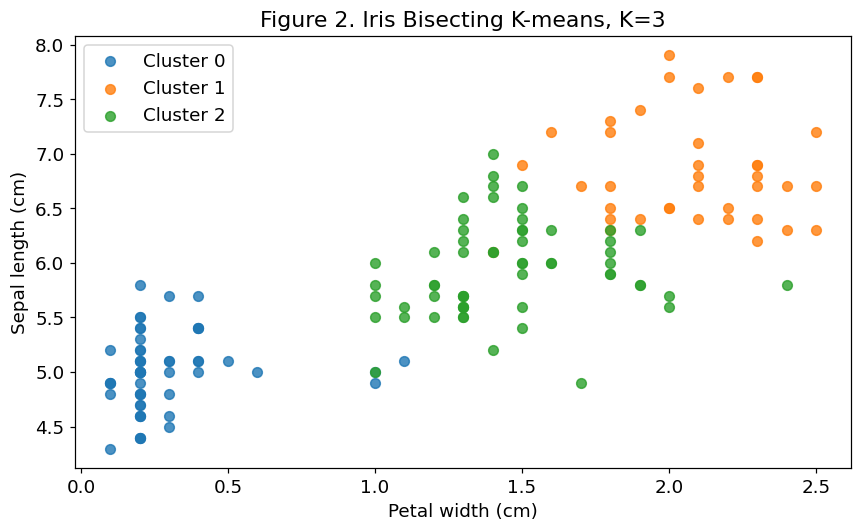

In [21]:
bisect = BisectingKMeans(n_clusters=3, n_init=20, random_state=42,
                        bisecting_strategy="biggest_inertia", max_iter=300, tol=1e-4)
bisect_labels = bisect.fit_predict(X_iris)
comparison = pd.DataFrame([
    {"method":"KMeans", "inertia":km.inertia_, "silhouette":silhouette_score(X_iris,km_labels)},
    {"method":"BisectingKMeans", "inertia":bisect.inertia_, "silhouette":silhouette_score(X_iris,bisect_labels)}])
display(comparison)
display(pd.Series(bisect_labels).value_counts().sort_index().rename("count").to_frame())
fig, ax = plt.subplots(figsize=(8,5))
for label in np.unique(bisect_labels):
    mask = bisect_labels == label
    ax.scatter(X_iris.loc[mask,"petal width"], X_iris.loc[mask,"sepal length"], label=f"Cluster {label}",s=40,alpha=.8)
ax.set(xlabel="Petal width (cm)",ylabel="Sepal length (cm)",title="Figure 2. Iris Bisecting K-means, K=3")
ax.legend(); plt.tight_layout(); plt.show()

Bisecting K-means gives group sizes of **53**, **38** and **59**. Its SSE is **84.224507** and its silhouette score is **0.540391**. Ordinary K-means has a lower SSE and a slightly higher silhouette score on these data. The early splits constrain the bisecting solution, which helps explain the difference. This result does not show that ordinary K-means will always perform better.

## Q3. DBSCAN
I chose DBSCAN because it can leave sparse observations unassigned and does not require a cluster count. It expands a group through core points, whose neighbourhoods contain at least `min_samples` observations, including the point itself. Border points can join a nearby core group but cannot expand it. Points outside all such groups receive label -1.

I standardised the four Iris measurements before fitting, using each column's mean and population standard deviation:

$$
z_{ij}=\frac{x_{ij}-\bar{x}_j}{s_j}.
$$

The radius therefore measures distance in standardised space. For example, a measurement of 7 with mean 5 and standard deviation 2 becomes 1. This prevents a feature with a larger spread from dominating the neighbourhood calculation.

I compared 24 combinations of `eps` and `min_samples`. I required at least 90% of the flowers to receive a cluster label and at least two non-noise groups, then selected the highest silhouette score among those candidates. The coverage threshold is my modelling choice. Species labels were not used to select the parameters.

In [22]:
iris_scaler = StandardScaler()
Z_iris = iris_scaler.fit_transform(X_iris)
db_rows = []
for min_points in [4,5,8,10]:
    for radius in [0.3,0.4,0.5,0.6,0.7,0.8]:
        labels = DBSCAN(eps=radius, min_samples=min_points).fit_predict(Z_iris)
        assigned = labels != -1
        n_clusters = len(set(labels[assigned]))
        score = silhouette_score(Z_iris[assigned],labels[assigned]) if 1 < n_clusters < assigned.sum() else np.nan
        db_rows.append({"eps":radius,"min_samples":min_points,"clusters":n_clusters,
                        "noise":int((~assigned).sum()),"coverage":assigned.mean(),"silhouette_assigned":score})
db_grid = pd.DataFrame(db_rows)
display(db_grid)
eligible = db_grid.loc[(db_grid.coverage >= .9) & (db_grid.clusters >= 2)]
choice = eligible.sort_values(["silhouette_assigned","eps","min_samples"],ascending=[False,True,True]).iloc[0]
db_iris = DBSCAN(eps=float(choice.eps), min_samples=int(choice.min_samples)).fit(Z_iris)
db_labels = db_iris.labels_
display(choice.to_frame().T.astype({"min_samples":int,"clusters":int,"noise":int}))
display(pd.Series(db_labels).value_counts().sort_index().rename("count").to_frame())
print("Core points:",len(db_iris.core_sample_indices_))
print("Noise count:",int((db_labels == -1).sum()))

,eps,min_samples,clusters,noise,coverage,silhouette_assigned
0,0.300000,4,5,107,0.286667,0.472553
1,0.400000,4,5,61,0.593333,0.500777
2,0.500000,4,2,34,0.773333,0.652305
3,0.600000,4,3,19,0.873333,0.547009
4,0.700000,4,2,6,0.960000,0.603455
5,0.800000,4,2,4,0.973333,0.596318
6,0.300000,5,3,120,0.200000,0.636797
7,0.400000,5,6,66,0.560000,0.485261
8,0.500000,5,2,35,0.766667,0.653199
9,0.600000,5,2,26,0.826667,0.640500


,eps,min_samples,clusters,noise,coverage,silhouette_assigned
10,0.700000,5,2,8,0.946667,0.610388


,count
-1,8
0,48
1,94


Core points: 126
Noise count: 8


The selected parameters are eps = **0.700000** and min_samples = **5**. They produce two clusters containing **48** and **94** flowers, with **8** noise points. Coverage is **0.946667**, and the silhouette score among assigned points is **0.610388**.

A higher silhouette score can be misleading when many points are excluded. For example, eps = **0.500000** and min_samples = **10** give a score of **0.709636**, but classify **89** flowers as noise. That configuration fails my coverage requirement.

Figure 3 marks the eight noise points with black crosses. The -1 label is excluded from the cluster count and silhouette calculation.

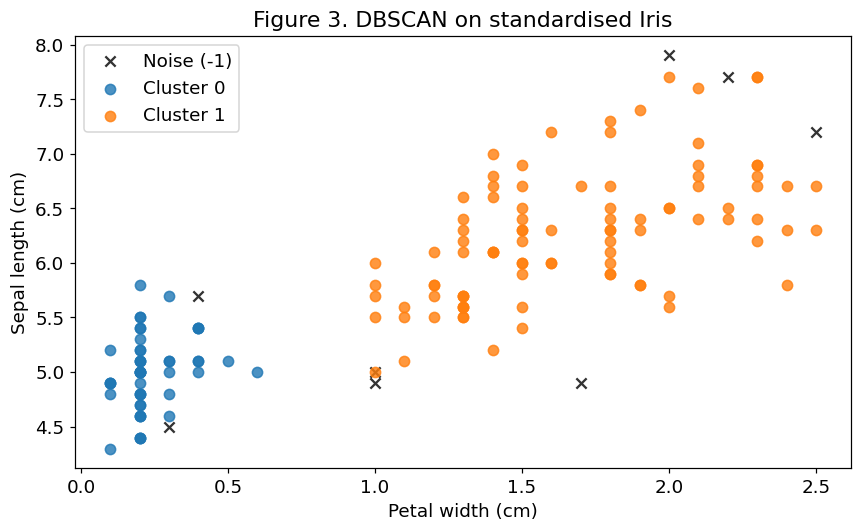

In [23]:
fig, ax = plt.subplots(figsize=(8,5))
for label in np.unique(db_labels):
    mask = db_labels == label
    options = {"color":"black","marker":"x"} if label == -1 else {"marker":"o"}
    ax.scatter(X_iris.loc[mask,"petal width"],X_iris.loc[mask,"sepal length"],
               label="Noise (-1)" if label == -1 else f"Cluster {label}",s=45,alpha=.8,**options)
ax.set(xlabel="Petal width (cm)",ylabel="Sepal length (cm)",title="Figure 3. DBSCAN on standardised Iris")
ax.legend(); plt.tight_layout(); plt.show()

DBSCAN separates the narrow-petal flowers from a larger connected group. It finds two groups here even though the dataset has three species. Smaller radii reject or fragment more points, while larger radii connect nearby groups. A single radius may also struggle when groups have different densities. The eight noise points are sparse under this parameter setting; they are not necessarily errors in the data.

## Q4. Comparing hierarchical linkage methods
The Section 2.5 figure uses the same four datasets, seed, scaling and cluster counts as the tutorial. Single linkage joins groups using their closest points, so it can follow a curve but is vulnerable to bridges between groups. Complete linkage uses the most distant pair and tends to produce groups with smaller diameters. Average linkage uses the mean distance between all pairs of points in the two groups.

Ward's method chooses the merge with the smallest increase in within-group SSE:

$$
\Delta J(A,B)=\frac{n_A n_B}{n_A+n_B}\|\mu_A-\mu_B\|^2.
$$

Here, $n_A$ and $n_B$ are the group sizes, and $\mu_A$ and $\mu_B$ are their centres. For sizes 2 and 3 with centres 0 and 4, the increase is $(6/5)\times16=19.200000$. This preference for compact groups explains much of Ward's behaviour in the figure.

| Data | My choice | What the figure shows |
|---|---|---|
| Moons | Single | It follows both curved moons. Average, Complete and Ward cut across parts of the curves. |
| Blobs | Ward | It separates the compact clouds clearly. Average and Complete also work well; Single joins two clouds and leaves a singleton. |
| Varied | Average | It handles the unequal spreads well. Ward is a close alternative in this run. Complete divides the diffuse cloud, while Single leaves one very large group. |
| Aniso | Average | It gives the most useful split of the elongated groups among these four methods, although some points are still mixed. Single joins almost everything together. |

I would start with Ward for compact groups in Euclidean space, Single for clearly separated curves with few bridging points, and Average when group shapes and spreads differ. Complete is useful when limiting group diameter matters. I would check the plot and group sizes before deciding: the Aniso result shows why an elongated shape alone is not enough reason to choose Single. The numerical comparison in Table A1 supports these observations.

## Q5. Choosing a method for Olist
### Dataset and algorithm
Our course project uses the Olist Brazilian e-commerce dataset. I chose K-means as a starting point for customer segmentation, using recency, frequency and monetary value (RFM). Recency is the number of days since the last purchase, frequency counts distinct delivered orders, and monetary value sums recorded payments in BRL. Payment totals can include freight, so they measure spending rather than profit.

| Method | Useful properties | Suitability for Olist |
|---|---|---|
| K-means | Fast fitting and centres that can be described in terms of customer features | My choice for a simple numeric RFM model, after adjusting for skew and scale |
| Bisecting K-means | Builds a sequence of coarse-to-fine splits | Useful if nested segments are needed, but early splits restrict later groups |
| Agglomerative | Shows relationships in a dendrogram | Easier to inspect on a sample; pairwise distances are expensive for about 93,000 buyers |
| DBSCAN | Finds irregular groups and labels sparse points as noise | A single radius is difficult to choose when customer densities differ; rare high-spending buyers may be rejected |
| Spectral | Can separate groups connected in a similarity graph | Dense similarity matrices are costly at this size, and the result is harder to explain |
| MiniBatch K-means | Fits an approximate K-means solution in smaller batches | A useful alternative for a larger dataset; ordinary K-means is feasible here |

These trade-offs follow the methods discussed in the tutorial and the [scikit-learn clustering comparison](https://scikit-learn.org/stable/auto_examples/cluster/plot_cluster_comparison.html). I have not benchmarked every method on Olist. The calculations below examine the K-means choice.

### Preparing customer features
I used `customer_unique_id` to identify repeat buyers. `customer_id` identifies an order-associated customer record and would miss purchases linked to another record. I summed payment rows by order before joining the tables, so an order with several payments still contributes only one order to frequency.

I retained delivered orders with recorded payments and used one day after the latest retained purchase date as the recency reference. This describes the completed dataset retrospectively. Final delivery statuses would not all have been available at that reference date, so the result should not be treated as a historical prediction.

In [24]:
orders = pd.read_csv(PROJECT_DATA / "olist_orders_dataset.csv", parse_dates=["order_purchase_timestamp"])
customers = pd.read_csv(PROJECT_DATA / "olist_customers_dataset.csv",usecols=["customer_id","customer_unique_id"])
payments = pd.read_csv(PROJECT_DATA / "olist_order_payments_dataset.csv")
assert orders.order_id.is_unique and customers.customer_id.is_unique
payment_per_order = payments.groupby("order_id",as_index=False)["payment_value"].sum()
delivered = orders.loc[orders.order_status.eq("delivered"),["order_id","customer_id","order_purchase_timestamp"]]
buyer_orders = delivered.merge(customers,on="customer_id",validate="many_to_one").merge(
    payment_per_order,on="order_id",how="left",validate="one_to_one")
print("Delivered orders without recorded payments:",int(buyer_orders.payment_value.isna().sum()))
buyer_orders = buyer_orders.dropna(subset=["payment_value","order_purchase_timestamp","customer_unique_id"])
reference_day = buyer_orders.order_purchase_timestamp.max().normalize() + pd.Timedelta(days=1)
buyer_summary = buyer_orders.groupby("customer_unique_id").agg(
    last_purchase=("order_purchase_timestamp","max"),frequency=("order_id","nunique"),monetary=("payment_value","sum"))
buyer_summary["recency"] = (reference_day - buyer_summary.last_purchase).dt.days
rfm = buyer_summary[["recency","frequency","monetary"]]
assert np.isfinite(rfm.to_numpy()).all() and (rfm >= 0).all().all()
assert rfm.frequency.sum() == len(buyer_orders)
print("Orders:",len(buyer_orders),"Buyers:",len(rfm),"Reference:",reference_day.date())
print(f"Repeat-buyer fraction: {(rfm.frequency > 1).mean():.6f}")
display(rfm.describe().drop(index="count"))

Delivered orders without recorded payments: 1
Orders: 96477 Buyers: 93357 Reference: 2018-08-30
Repeat-buyer fraction: 0.030003


,recency,frequency,monetary
mean,237.473794,1.033420,165.198772
std,152.587931,0.209099,226.314579
min,0.000000,1.000000,9.590000
25%,114.000000,1.000000,63.060000
50%,218.000000,1.000000,107.780000
75%,346.000000,1.000000,182.560000
max,695.000000,15.000000,13664.080000


The retained data contain **96,477** orders from **93,357** buyers. One delivered order has no payment record and is excluded. The recency reference is **2018-08-30**, and only **0.030003** of the buyers have more than one observed delivered order.

### Choosing the number of groups
I applied `log1p` to reduce the influence of large values, then standardised each feature. Without these adjustments, spending could dominate differences measured in days and order counts.

I fitted K = 2–6 using the same data, seed and 20 starts. I compared silhouette scores on the same random sample of 5,000 buyers to limit the cost of calculating pairwise distances. These scores describe the fitted data; they are not held-out prediction scores. SSE alone would not select K because it normally decreases as more groups are added.

In [25]:
rfm_scaler = StandardScaler()
Z_rfm = rfm_scaler.fit_transform(np.log1p(rfm))
project_models = {}
k_rows = []
for k in range(2,7):
    model = KMeans(n_clusters=k,n_init=20,random_state=42,max_iter=300).fit(Z_rfm)
    project_models[k] = model
    k_rows.append({"K":k,"SSE":model.inertia_,"sampled_silhouette":silhouette_score(
        Z_rfm,model.labels_,sample_size=5000,random_state=42)})
k_table = pd.DataFrame(k_rows)
display(k_table)
chosen_k = int(k_table.loc[k_table.sampled_silhouette.idxmax(),"K"])
project_model = project_models[chosen_k]
print("Selected K:",chosen_k)

,K,SSE,sampled_silhouette
0,2,190211.943689,0.705053
1,3,129260.207419,0.418818
2,4,82927.163961,0.403256
3,5,68339.585152,0.359208
4,6,58447.027553,0.358145


Selected K: 2


K = **2** gives the highest sampled silhouette, **0.705053**, compared with **0.418818** for K = 3. I retained two groups for the initial model and inspected their profiles in the original units. The high score needs some care: frequency is almost always one, so standardising it can give the small repeat-buyer group considerable influence.

### Customer profiles
I used medians for recency and spending to reduce the effect of extreme observations in the summaries. Figure 4 displays 5,000 sampled buyers for readability; the model was fitted to all retained buyers.

,buyers,recency_median_days,frequency_mean,monetary_median_BRL
cluster,,,,
0,90556,219.000000,1.000000,105.390000
1,2801,199.000000,2.113888,225.550000


repeat buyer,False,True
cluster,,
0,90556,0
1,0,2801


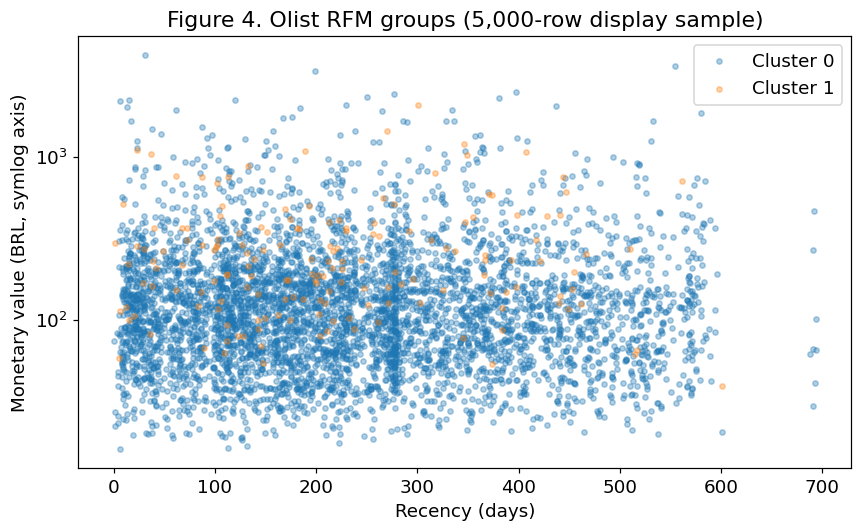

In [26]:
profile = rfm.assign(cluster=project_model.labels_).groupby("cluster").agg(
    buyers=("frequency","size"),recency_median_days=("recency","median"),
    frequency_mean=("frequency","mean"),monetary_median_BRL=("monetary","median"))
display(profile)
repeat_crosstab = pd.crosstab(project_model.labels_,rfm.frequency.gt(1),rownames=["cluster"],colnames=["repeat buyer"])
display(repeat_crosstab)
plot_sample = np.random.default_rng(42).choice(len(rfm),size=5000,replace=False)
fig,ax = plt.subplots(figsize=(8,5))
for label in np.unique(project_model.labels_):
    positions = plot_sample[project_model.labels_[plot_sample] == label]
    ax.scatter(rfm.iloc[positions].recency,rfm.iloc[positions].monetary,s=12,alpha=.35,label=f"Cluster {label}")
ax.set_yscale("symlog",linthresh=1)
ax.set(xlabel="Recency (days)",ylabel="Monetary value (BRL, symlog axis)",title="Figure 4. Olist RFM groups (5,000-row display sample)")
ax.legend(); plt.tight_layout(); plt.show()

The two groups match the one-time and repeat buyers exactly. Cluster 0 contains **90,556** buyers with one delivered order; cluster 1 contains all **2,801** repeat buyers. Median spending is 105.390000 BRL and 225.550000 BRL, respectively. Median recency is **219.000000** and **199.000000** days.

This is easy to interpret, but at K = 2, K-means adds little beyond a direct rule based on whether a buyer has returned. The groups could help frame a retention test, such as encouraging a second purchase, but the clustering cannot show that an offer would work.

There are also differences in observation time: earlier buyers have had longer to place another order. Purchases outside Olist are unavailable, and the final delivery filter makes this a retrospective analysis. I would keep K-means as a baseline, then evaluate any proposed customer action with later data or an experiment.

## Additional analysis
### Checking the distance calculation
I independently recalculated Iris SSE from the fitted labels and centres. I also checked the update steps on points 0, 2, 8 and 10, starting with centres 0 and 8. The first update moves the centres to 1 and 9; the second leaves them unchanged. The final SSE is 4.

In [27]:
sse_check = ((X_iris.to_numpy() - km.cluster_centers_[km_labels]) ** 2).sum()
assert np.isclose(sse_check,km.inertia_)
print(f"Independently recomputed Iris SSE: {sse_check:.6f}")
small_x = np.array([0.,2.,8.,10.])
small_centres = np.array([0.,8.])
steps = []
for iteration in range(1,11):
    distances = (small_x[:,None] - small_centres[None,:]) ** 2
    small_labels = distances.argmin(axis=1)
    updated = np.array([small_x[small_labels == j].mean() for j in range(2)])
    steps.append({"iteration":iteration,"labels":small_labels.tolist(),"old centres":small_centres.tolist(),"new centres":updated.tolist()})
    stopped = np.allclose(updated,small_centres)
    small_centres = updated
    if stopped:
        break
display(pd.DataFrame(steps))
print(f"Small example SSE: {((small_x-small_centres[small_labels])**2).sum():.6f}")
print("DBSCAN small-example labels:",DBSCAN(eps=.15,min_samples=3).fit_predict(np.array([[0],[.1],[.2],[2]])))

Independently recomputed Iris SSE: 78.940841


,iteration,labels,old centres,new centres
0,1,"[0, 0, 1, 1]","[0.0, 8.0]","[1.0, 9.0]"
1,2,"[0, 0, 1, 1]","[1.0, 9.0]","[1.0, 9.0]"


Small example SSE: 4.000000
DBSCAN small-example labels: [ 0  0  0 -1]


The independent Iris SSE calculation gives **78.940841**, matching the fitted model. The small example stops at centres 1 and 9 with SSE **4.000000**. In the DBSCAN example, the first three nearby points share a group and the isolated point receives -1.

### Checking the linkage comparison
The synthetic datasets have known generating labels, which allow a numerical check of the Section 2.5 figure. I used the adjusted Rand index (ARI), which compares whether pairs of points belong together and adjusts for agreement by chance. It is unchanged if the cluster numbers are renamed. A value of 1 indicates identical partitions.

The generating labels are used only to evaluate these synthetic results, not to fit the models. This check is unavailable for Olist because its customer segments have no known correct labels.

In [28]:
shape_data = {
    "Moons":toy_datasets.make_moons(n_samples=1000,noise=.05,random_state=170),
    "Blobs":toy_datasets.make_blobs(n_samples=1000,random_state=170),
    "Varied":toy_datasets.make_blobs(n_samples=1000,cluster_std=[1.,2.5,.5],random_state=170)}
aniso_x, aniso_truth = toy_datasets.make_blobs(n_samples=1000,random_state=170)
shape_data["Aniso"] = (aniso_x @ np.array([[.6,-.6],[-.4,.8]]),aniso_truth)
link_rows = []
for name,(points,truth) in shape_data.items():
    z = StandardScaler().fit_transform(points)
    for method in ["single","average","complete","ward"]:
        labels = AgglomerativeClustering(n_clusters=len(np.unique(truth)),linkage=method).fit_predict(z)
        link_rows.append({"dataset":name,"linkage":method,"ARI":adjusted_rand_score(truth,labels),
                          "cluster sizes":pd.Series(labels).value_counts().sort_values().tolist()})
link_table = pd.DataFrame(link_rows)
display(Markdown("Table A1. Agreement and group sizes for the original linkage grid"))
display(link_table.pivot(index="dataset",columns="linkage",values="ARI"))
display(link_table[["dataset","linkage","cluster sizes"]])

Table A1. Agreement and group sizes for the original linkage grid

linkage,average,complete,single,ward
dataset,,,,
Aniso,0.699463,0.540655,-0.000004,0.538090
Blobs,0.979134,0.961528,0.570201,0.997002
Moons,0.598695,0.467323,1.000000,0.598695
Varied,0.949926,0.525413,0.000008,0.941469


,dataset,linkage,cluster sizes
0,Moons,single,"[500, 500]"
1,Moons,average,"[387, 613]"
2,Moons,complete,"[496, 504]"
3,Moons,ward,"[387, 613]"
4,Blobs,single,"[1, 333, 666]"
5,Blobs,average,"[326, 335, 339]"
6,Blobs,complete,"[320, 337, 343]"
7,Blobs,ward,"[332, 334, 334]"
8,Varied,single,"[1, 1, 998]"
9,Varied,average,"[326, 335, 339]"


Table A1 agrees with the figure. Single recovers the Moons groups with ARI **1.000000**, and Ward scores **0.997002** on Blobs. Average has the highest score on Varied (**0.949926**) and Aniso (**0.699463**). Single produces groups of **998**, **1** and **1** on both Varied and Aniso, so it is a poor choice for those two examples. Different noise levels or scaling could change this ranking.

### Sensitivity checks
I changed the scale of the Iris features while keeping K and the initialisation settings fixed. For Olist, I repeated the selected K = 2 fit with four other seeds. I also inspected K = 3 to see what extra detail it provided.

In [29]:
scaled_iris_labels = KMeans(n_clusters=3,n_init=20,random_state=42).fit_predict(Z_iris)
print(f"Iris raw/scaled assignment ARI: {adjusted_rand_score(km_labels,scaled_iris_labels):.6f}")
stability = []
for seed in [0,1,7,99]:
    labels = KMeans(n_clusters=chosen_k,n_init=20,random_state=seed).fit_predict(Z_rfm)
    stability.append({"seed":seed,"ARI vs seed 42":adjusted_rand_score(project_model.labels_,labels)})
display(Markdown("Table A2. Olist K=2 initialisation stability"))
display(pd.DataFrame(stability))
profile_three = rfm.assign(cluster=project_models[3].labels_).groupby("cluster").agg(
    buyers=("frequency","size"),recency_median_days=("recency","median"),
    frequency_mean=("frequency","mean"),monetary_median_BRL=("monetary","median"))
display(Markdown("Table A3. Exploratory K=3 customer profiles"))
display(profile_three)

Iris raw/scaled assignment ARI: 0.803612


Table A2. Olist K=2 initialisation stability

,seed,ARI vs seed 42
0,0,1.000000
1,1,1.000000
2,7,1.000000
3,99,1.000000


Table A3. Exploratory K=3 customer profiles

,buyers,recency_median_days,frequency_mean,monetary_median_BRL
cluster,,,,
0,19093,44.000000,1.000000,108.430000
1,71463,270.000000,1.000000,104.870000
2,2801,199.000000,2.113888,225.550000


Standardising Iris changes the partition: its ARI against the original-scale result is **0.803612**. The four Olist runs with different seeds all give ARI **1.000000** against the selected K = 2 result. This result is stable to those initialisations, although it may still change with the data or feature definitions.

At K = 3, the one-time buyers split into **19,093** recent buyers and **71,463** earlier buyers, with median recency of **44.000000** and **270.000000** days. The **2,801** repeat buyers remain together. This extra split could be useful for a campaign aimed at recent versus older one-time buyers, even though its silhouette score is lower. I would choose it only if that distinction served the business question.

I used OpenAI Codex to assist with this assignment.